In [113]:
import jax_sn as jsn
%load_ext autoreload
%autoreload 2
import jax_sbgeom

import jax.numpy as jnp
import numpy as onp
from typing import Tuple
import jax
import numpy as onp
from functools import partial
jax.config.update("jax_enable_x64", True)
from jax_sn.operators.transport_operator import TransportOperatorBatched, TransportOperatorMultipleAnglesVmap, TransportOperatorVmap, TransportOperatorBatchedPallas, TransportOperatorMultipleAngles
from jax_sn.domain.geometric_domain import Domain, TopologicalSortedAngle
from jax_sn.domain.cross_sections import CrossSectionData
from jax_sn.solution_domain.basix_fem import BasixLagrangianSimplex
from jax_sn.operators.mass_operator import MassOperator
from jax_sn.solution_domain.solution_domain import SolutionDomain
from jax_sn.operators.moment_operator import MomentOperator, DiscreteOperator
from jax_sn.operators.scatter_operator import GatherScatterOperatorBroadcasted
from jax_sn.operators.multi_group_operator import MultiGroupOperatorScan
from jax_sn.operators.multi_group_operator import MultiGroupLowerTriangularBlockSolver
from jax_sn.tools.memory_analysis import MultiGroupOperatorSigmaAllParametrised, _filter_jit_f_to_memory, OperatorAnalysis, pytree_nbytes, MultiGroupOperatorEverythingParametrised

from jax_sn.domain.cross_sections import CrossSectionsIndexed
import equinox as eqx
from typing import List
from jax_sn.tools.mesh_tools import _pad_last_dimension
import matplotlib.pyplot as plt
from dataclasses import dataclass
onp.set_printoptions(linewidth = 200)
from finite_elements.test_moment_scatter_operator import _setup_all_sb
from functions_for_testing import solve_and_plot

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [34]:
from jax_sn.domain.domain_generation import create_cartesian_setup
from jax_sn.solution_domain import BasixLagrangianSimplex
from jax_sn.solution_domain import SolutionDomain
from jax_sn.domain import CrossSectionData, Domain
from jax_sn.source import Source
from jax_sn.tools.memory_analysis import _filter_jit_f_to_memory
import lineax as lx

In [118]:

import jax_sn
def _get_bb_verts_conn_xs_sources(dim, d_elem_regions, n_elem_regions, d_other_dim, n_other_dim):
    from finite_elements.test_breeding_blanket import bb_data_dict
    data_dictionary = bb_data_dict() # dictionary with matrices
    xs_data_dict = {name : CrossSectionData(total = jnp.array(data_dictionary[name][0]), scattering = jnp.array(data_dictionary[name][1])) for name in data_dictionary.keys()}    
    other_dims   = [[(d_other_dim, n_other_dim)]]*(dim - 1)
    region_names = ['Plasma', 'TungstenArmor', 'FirstWall', 'BreedingZone','BackSupportingStructure', 'VVWallFront', 'VVShield', 'VVWallBack']
    xs_regions = [xs_data_dict[i] for i in region_names]
    region_size_res = [(size, n_elem) for size, n_elem in zip(d_elem_regions, n_elem_regions)]    
    source_eg0 = [1 if i ==0 else 0 for i in range(len(region_names))]

    verts, conn, cross_sections, sources = create_cartesian_setup(dim, [region_size_res] + other_dims, xs_regions, source_eg0, 0)
    return verts, conn, cross_sections, sources

def setup_from_verts(verts, conn, cross_sections, sources,  degree, tn_order):        
    element_type                         = BasixLagrangianSimplex(degree, verts.shape[-1])
    domain                               = Domain.from_mesh_and_cross_sections((verts, conn), element_type.face_template, cross_sections)    
    solution_domain                      = SolutionDomain.from_element_and_domain(element_type, domain)
    # isotropic flat source
    sources = jnp.repeat(sources, repeats = solution_domain.n_basis, axis = -1).reshape(-1, solution_domain.n_basis)

    return solution_domain, sources, jax_sn.quadrature_set.create_tn_quadrature_set(tn_order)

def _setup_operators(solution_domain: SolutionDomain, sources: jnp.ndarray, quadrature_set: jax_sn.quadrature_set.QuadratureSet, batch_size = 100) -> Tuple[MultiGroupOperatorScan, jnp.ndarray, SolutionDomain]:        
    n_energy_groups           = solution_domain.domain.cross_sections_indexed.n_energy_groups
    lmax                      = solution_domain.domain.cross_sections_indexed.l_max

    topological_sorted_angles = TopologicalSortedAngle.from_domain_quadrature_set(solution_domain.domain, quadrature_set, n_iterations_per_loop = 100)
    transport_operator        = TransportOperatorMultipleAnglesVmap(TransportOperatorBatched(solution_domain.solution_domain_data, topological_sorted_angles, 0, batch_size))
    mass_operator             = MassOperator.from_transport_operator(transport_operator)
    moment_operator           = MomentOperator.from_quadrature_set(quadrature_set, l_max = lmax, elements_basis_shape=solution_domain.elements_basis_shape)    
    discrete_operator         = DiscreteOperator.from_quadrature_set(quadrature_set, l_max = lmax, elements_basis_shape=solution_domain.elements_basis_shape)
    gather_scatter_operator   = GatherScatterOperatorBroadcasted(cross_sections_indexed=solution_domain.domain.cross_sections_indexed)
    source_total              = jnp.broadcast_to(sources[None, :, :], (topological_sorted_angles.angle.shape[0],) + sources.shape) # source for all angles
    Aop                       = MultiGroupOperatorScan(moment_operator, discrete_operator, transport_operator, mass_operator, gather_scatter_operator, n_energy_groups)
    return Aop.convert_to_lower_block_triangular(), source_total, solution_domain

@eqx.filter_jit
def get_rhs(MGOP, source_eg0):
    rhs_eg0 = MGOP.moment_operator.mv(MGOP.transport_operator.inv(MGOP.mass_operator.mv(source_eg0)))

    rhs_total = jnp.stack([rhs_eg0] + [jnp.zeros_like(rhs_eg0) for _ in range(MGOP.n_energy_groups -1)], axis=0)
    return rhs_total


#_get_bb_verts_conn_xs_sources(2, base_region_sizes(), base_resolutions(), 5.0, 1)

In [115]:
from finite_elements.test_breeding_blanket import bb_data_dict, base_region_sizes, base_resolutions,  _get_bb_args, _setup_bb_args, _get_bb_args


def modify_setup_mgop(dim, degree, modify_verts_xs):
    verts, conn, cross_sections, sources = _get_bb_verts_conn_xs_sources(dim, base_region_sizes(), base_resolutions(), 5.0, 1)
    verts, cross_sections = modify_verts_xs(verts, cross_sections)

    solution_domain, sources, quadrature_set = setup_from_verts(verts, conn, cross_sections, sources, degree, 3)
    
    return _setup_operators(solution_domain, sources, quadrature_set)    

bicgstab_solver = lx.BiCGStab(1e-12, 1e-12, max_steps = 160)
lower_triangular_solver = MultiGroupLowerTriangularBlockSolver(bicgstab_solver)
MGOP, source_eg0, sol_domain_2 = modify_setup_mgop(2,2, lambda v,c : (v,c))
rhs = get_rhs(MGOP, source_eg0)

In [187]:
@eqx.filter_jit
def solve_and_sum(MGOP, rhs, solver):
    solution = lx.linear_solve(MGOP, rhs, solver)
    return jnp.sum(solution.value)


theta_everything_base = MultiGroupOperatorEverythingParametrised.theta_base(MGOP)

@eqx.filter_jit
def solve_result_everything(theta, MGOP, rhs_base, ltri_solver):    
    MGOP_new = MultiGroupOperatorEverythingParametrised.reconstruct_operator(MGOP, theta)
    solution_value =  lx.linear_solve(MGOP_new, rhs_base, solver=ltri_solver).value
    return jnp.sum(solution_value)

grad_theta_everything = eqx.filter_jit(jax.grad(solve_result_everything, argnums=0))
df_dxi = grad_theta_everything(theta_everything_base, MGOP, rhs, lower_triangular_solver)

In [209]:
def _modify_vertices_00(verts, xs, dx, vert_mod):
    verts = verts.at[vert_mod].set(verts[vert_mod] + jnp.array([dx, 0.0]))
    return verts, xs

def _modify_xs(verts, xs, dx, xs_mod, total = True):
    
    if total:
        xs = eqx.tree_at(lambda x : x.cross_section_data.total, xs, replace_fn=lambda t : t.at[xs_mod].set(t[xs_mod] + dx)) 
    else:
        xs = eqx.tree_at(lambda x : x.cross_section_data.scattering, xs, replace_fn=lambda t : t.at[xs_mod].set(t[xs_mod] + dx)) 
    return verts, xs

dx = 1e-3
vert_mod = 14
modifier_func = lambda v,c : _modify_vertices_00(v,c, dx, vert_mod)

xs_mod = (3,3, 0,0)
modifier_func  = lambda v,c : _modify_xs(v,c, dx, xs_mod, total = False)

f_0 = solve_and_sum(MGOP, rhs, lower_triangular_solver)
MGOP_dx = modify_setup_mgop(2,2, modifier_func)[0]
f_1 = solve_and_sum(MGOP_dx, rhs, lower_triangular_solver)
df_dx = (f_1 - f_0)/dx
print("Finite difference df/dx: ", df_dx)

Finite difference df/dx:  -0.06673699868997574


In [213]:
from finite_elements.test_multigroup_derivative import test_mg_ad

In [228]:
test_mg_ad()

Testing case: functools.partial(<function _modify_vertices at 0x73d55277a3e0>, dx=0.0001, vert_mod=0) <function f_cases.<locals>.<lambda> at 0x73d55200ae80>
Finite diff: -0.7497854358007316
AD         : -0.7496111274454744
Testing case: functools.partial(<function _modify_vertices at 0x73d55277a3e0>, dx=0.0001, vert_mod=5) <function f_cases.<locals>.<lambda> at 0x73d5520096c0>
Finite diff: 6.7252757108349215
AD         : 6.724628710798379
Testing case: functools.partial(<function _modify_vertices at 0x73d55277a3e0>, dx=0.0001, vert_mod=25) <function f_cases.<locals>.<lambda> at 0x73d55200aac0>
Finite diff: -9.68009084061805
AD         : -9.681729610732077
Testing case: functools.partial(<function _modify_xs at 0x73d55277b240>, dx=0.0001, xs_mod=(0, 0), total=True) <function f_cases.<locals>.<lambda> at 0x73d55200ade0>
Finite diff: -16.35940943657488
AD         : -16.36006216444312
Testing case: functools.partial(<function _modify_xs at 0x73d55277b240>, dx=0.0001, xs_mod=(3, 3), total=T

In [206]:
df_dxi.cross_section_data.scattering[3,3,0,0]

Array(-0.0667337, dtype=float64)

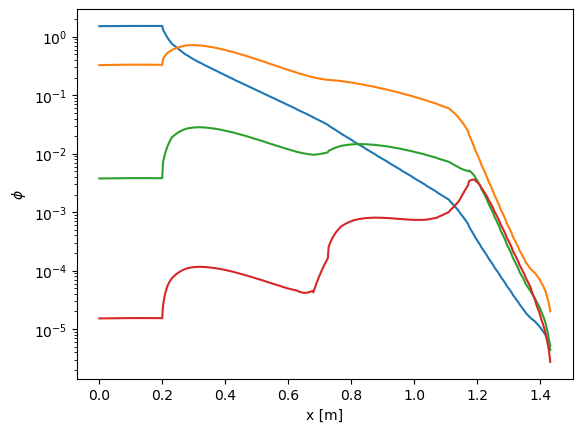

In [199]:
# We keep the right-hand-side fixed. This is unphysical, as the transport operator will depend on the parametrization. In principle a straightforward extension but we don't do that here.
MGOP, source_eg0, sol_domain_2 = modify_setup_mgop(2,2, lambda v,c : (v,c))
rhs = get_rhs(MGOP, source_eg0)
solve_and_plot(MGOP, rhs, sol_domain_2, lower_triangular_solver)

In [ ]:
# theta_base      = MultiGroupOperatorSigmaAllParametrised.theta_base(MGOP)
# MGOP_re         = MultiGroupOperatorSigmaAllParametrised.reconstruct_operator(MGOP, theta_base)
# rhs_base        = jnp.ones_like(MGOP.in_structure())
# bicgstab_solver = lx.BiCGStab(1e-12, 1e-12, max_steps = 160)


In [56]:
# We want to isolate the batching here. This is a memory cost independent of the operator size.
MGOP_no_batch= eqx.tree_at(lambda op : op.transport_operator.transport_operator.batch_size , MGOP, replace = 1)

In [57]:
MGOP.n_elements

500

In [58]:
@eqx.filter_jit
def solve_fwd(mgop, rhs, solver):
    return lx.linear_solve(mgop, rhs, solver=solver).value


@eqx.filter_jit
def solve_lower_tri(mgop, rhs, solver):
    ltri_solver=  MultiGroupLowerTriangularBlockSolver(solver)
    return lx.linear_solve(mgop, rhs, solver=ltri_solver).value

@eqx.filter_jit
def solve_bwd(mgop, rhs, solver):    
    return lx.linear_solve(mgop.transpose(), rhs, solver=solver).value

@eqx.filter_jit
def solve_bwd_lower_tri(mgop, rhs, solver):    
    ltri_solver=  MultiGroupLowerTriangularBlockSolver(solver)
    return lx.linear_solve(mgop.transpose(), rhs, solver=ltri_solver).value

def print_costs_solves(MGOP, rhs_base, bicgstab_solver):
    sgop = MGOP.to_single_group_operator(0)
    rhs_base = jnp.ones_like(MGOP.in_structure())
    bicgstab_solver = lx.BiCGStab(1e-12, 1e-12, max_steps = 160)
    print("Transport Operator")
    print(OperatorAnalysis.analyze_memory(sgop.transport_operator, "inv"))
    print("Single group operator")
    print(OperatorAnalysis.analyze_memory(sgop, "mv"))
    print("Multi group operator")
    print(OperatorAnalysis.analyze_memory(MGOP, "mv"))
    print("Forward solve")
    print(_filter_jit_f_to_memory(solve_fwd, MGOP, rhs_base, bicgstab_solver ))
    print("Forward tri solve")
    print(_filter_jit_f_to_memory(solve_lower_tri, MGOP, rhs_base, bicgstab_solver ))

    print("Backward solve")
    print(_filter_jit_f_to_memory(solve_bwd, MGOP, rhs_base, bicgstab_solver ))
    print("Backward tri solve")
    print(_filter_jit_f_to_memory(solve_bwd_lower_tri, MGOP, rhs_base, bicgstab_solver ))
print_costs_solves(MGOP_no_batch, rhs_base, bicgstab_solver)


Transport Operator
{'peak': 4.080230712890625, 'argument': 2.34576416015625, 'output': 1.6479721069335938, 'temp': 0.08850860595703125}
Single group operator
{'peak': 7.3433685302734375, 'argument': 1.575103759765625, 'output': 0.8239974975585938, 'temp': 4.946662902832031}
Multi group operator
{'peak': 12.287528991699219, 'argument': 4.047027587890625, 'output': 3.2959213256835938, 'temp': 4.947700500488281}
Forward solve
{'peak': 33.76802158355713, 'argument': 4.0999908447265625, 'output': 3.2959213256835938, 'temp': 28.027099609375}
Forward tri solve
{'peak': 18.936302185058594, 'argument': 4.0999908447265625, 'output': 3.2959213256835938, 'temp': 11.710212707519531}
Backward solve
{'peak': 39.007752418518066, 'argument': 4.0999908447265625, 'output': 3.2959213256835938, 'temp': 32.972900390625}
Backward tri solve
{'peak': 23.61260986328125, 'argument': 4.0999908447265625, 'output': 3.2959213256835938, 'temp': 17.09693145751953}


In [49]:
@eqx.filter_jit
def solve_result(theta, MGOP, rhs_base, ltri_solver):    

    MGOP_new = MultiGroupOperatorSigmaAllParametrised.reconstruct_operator(MGOP, theta)
    solution_value =  lx.linear_solve(MGOP_new, rhs_base, solver=ltri_solver).value
    return jnp.sum(solution_value)

grad_theta = eqx.filter_jit(jax.grad(solve_result, argnums=0))

ltri_solver = MultiGroupLowerTriangularBlockSolver(bicgstab_solver)

In [105]:
from jax_sn.tools.memory_analysis import OperatorThetaParametrised
from jax_sn.solution_domain import PrecomputedGeometricData
from jax_sn.domain.cross_sections import CrossSectionData
from jax_sn.domain.geometric_domain import compute_face_normal_vectors_from_3d_simplices
from jax_sn.solution_domain.basix_fem import _precompute_jacobians_simplex

class EverythingTheta(eqx.Module):
    vertices : jnp.ndarray 
    cross_section_data: CrossSectionData

class MultiGroupOperatorEverythingParametrised(OperatorThetaParametrised):
    '''
    Parametrisation case for total operators parameterised by the total and scattering cross section.
    '''
    @staticmethod
    def theta_base(operator ):
        return EverythingTheta(operator.transport_operator.solution_domain_data.domain.vertices, operator.transport_operator.solution_domain_data.domain.cross_sections_indexed.cross_section_data)
    
    @staticmethod
    def reconstruct_operator(operator, theta):

        # We have to replace:
        # 1. cross sections
        xs_idxed             = eqx.tree_at(lambda xs_idx : xs_idx.cross_section_data, operator.transport_operator.solution_domain_data.domain.cross_sections_indexed, replace = theta.cross_section_data)                
        operator_xs_replaced =  eqx.tree_at(operator.cross_sections_indexed_loc, operator, replace_fn= lambda _ :  xs_idxed)

        # 2. domain itself
        domain = operator_xs_replaced.transport_operator.solution_domain_data.domain
        #       -  Face normals in the domain & vertices in the domain (although they don't do anything anymore i think...)
        face_normals = compute_face_normal_vectors_from_3d_simplices(theta.vertices[domain.connectivity], domain.face_template)
        domain_replaced = eqx.tree_at(lambda d : [d.vertices, d.face_normals], domain, replace = [theta.vertices, face_normals])        
        operator_xs_dom_replaced = eqx.tree_at(lambda op : op.transport_operator.transport_operator.solution_domain_data.domain, operator_xs_replaced, replace = domain_replaced)

        # 3. precomputed geometric data
        precomputed_geometric_data_comp = _precompute_jacobians_simplex(domain_replaced)
        
        return eqx.tree_at(operator_xs_dom_replaced.precomputed_geometric_data_loc, operator_xs_dom_replaced, replace_fn= lambda _ : precomputed_geometric_data_comp)

theta_everything_base = MultiGroupOperatorEverythingParametrised.theta_base(MGOP)

@eqx.filter_jit
def solve_result_everything(theta, MGOP, rhs_base, ltri_solver):    
    MGOP_new = MultiGroupOperatorEverythingParametrised.reconstruct_operator(MGOP, theta)
    solution_value =  lx.linear_solve(MGOP_new, rhs_base, solver=ltri_solver).value
    return jnp.sum(solution_value)

grad_theta_everything = eqx.filter_jit(jax.grad(solve_result_everything, argnums=0))

In [52]:
print("Everything parametrised")
theta_everything_base = MultiGroupOperatorEverythingParametrised.theta_base(MGOP)
print("Tri solver (batch 100)", _filter_jit_f_to_memory(solve_result_everything, theta_everything_base, MGOP, rhs_base, ltri_solver))
print("Tri solver (batch 1)", _filter_jit_f_to_memory(solve_result_everything, theta_everything_base, MGOP_no_batch, rhs_base, ltri_solver))
print("Total solver (batch 100 )", _filter_jit_f_to_memory(solve_result_everything, theta_everything_base, MGOP, rhs_base, bicgstab_solver))
print("Total solver (batch 1)"  ,  _filter_jit_f_to_memory(solve_result_everything,theta_everything_base, MGOP_no_batch, rhs_base, bicgstab_solver))

print("\nGradients:")
print("Tri solver (batch 100)", _filter_jit_f_to_memory(grad_theta_everything, theta_everything_base, MGOP, rhs_base, ltri_solver))
print("Tri solver (batch 1)", _filter_jit_f_to_memory(grad_theta_everything, theta_everything_base, MGOP_no_batch, rhs_base, ltri_solver))
print("Total solver (batch 100 )", _filter_jit_f_to_memory(grad_theta_everything, theta_everything_base, MGOP, rhs_base, bicgstab_solver))
print("Total solver (batch 1)"  ,  _filter_jit_f_to_memory(grad_theta_everything, theta_everything_base, MGOP_no_batch, rhs_base, bicgstab_solver))


Everything parametrised
Tri solver (batch 100) {'peak': 895.0919504165649, 'argument': 183.50254821777344, 'output': 3.0517578125e-05, 'temp': 790.0048751831055}
Tri solver (batch 1) {'peak': 849.7763595581055, 'argument': 183.50254821777344, 'output': 3.0517578125e-05, 'temp': 748.8080978393555}
Total solver (batch 100 ) {'peak': 1669.6336145401, 'argument': 183.50254821777344, 'output': 3.0517578125e-05, 'temp': 1486.145980834961}
Total solver (batch 1) {'peak': 1669.636643409729, 'argument': 183.50254821777344, 'output': 3.0517578125e-05, 'temp': 1486.148422241211}

Gradients:
Tri solver (batch 100) {'peak': 10868.808479309082, 'argument': 183.50254821777344, 'output': 0.07814788818359375, 'temp': 10685.278221130371}
Tri solver (batch 1) {'peak': 13419.879306793213, 'argument': 183.50254821777344, 'output': 0.07814788818359375, 'temp': 13236.363670349121}
Total solver (batch 100 ) {'peak': 11525.307151794434, 'argument': 183.50254821777344, 'output': 0.07814788818359375, 'temp': 113

In [ ]:
Transport Operator
{'peak': 187.67538452148438, 'argument': 104.98715209960938, 'output': 82.3974838256836, 'temp': 0.29334259033203125}
Single group operator
{'peak': 270.2335968017578, 'argument': 64.0634765625, 'output': 41.198753356933594, 'temp': 164.97449493408203}
Multi group operator
{'peak': 521.3679885864258, 'argument': 187.65966796875, 'output': 164.7949447631836, 'temp': 168.91693878173828}
Forward solve
{'peak': 1673.4192895889282, 'argument': 190.2606658935547, 'output': 164.7949447631836, 'temp': 1318.375732421875}
Forward tri solve
{'peak': 853.5590133666992, 'argument': 190.2606658935547, 'output': 164.7949447631836, 'temp': 581.0356521606445}
Backward solve
{'peak': 1850.4557428359985, 'argument': 190.2606658935547, 'output': 164.7949447631836, 'temp': 1495.4140625}
Backward tri solve
{'peak': 1076.3215637207031, 'argument': 190.2606658935547, 'output': 164.7949447631836, 'temp': 758.7087478637695}
Everything parametrised
Tri solver (batch 100) {'peak': 24.70159149169922, 'argument': 3.9641876220703125, 'output': 3.0517578125e-05, 'temp': 21.85350799560547}
Tri solver (batch 1) {'peak': 18.86534881591797, 'argument': 3.9641876220703125, 'output': 3.0517578125e-05, 'temp': 15.072257995605469}
Total solver (batch 100 ) {'peak': 38.572007179260254, 'argument': 3.9641876220703125, 'output': 3.0517578125e-05, 'temp': 37.65306091308594}
Total solver (batch 1) {'peak': 33.697068214416504, 'argument': 3.9641876220703125, 'output': 3.0517578125e-05, 'temp': 31.389389038085938}

Gradients:
Tri solver (batch 100) {'peak': 140.08175659179688, 'argument': 3.9641876220703125, 'output': 0.01050567626953125, 'temp': 136.84829711914062}
Tri solver (batch 1) {'peak': 147.00969314575195, 'argument': 3.9641876220703125, 'output': 0.01050567626953125, 'temp': 143.07363891601562}
Total solver (batch 100 ) {'peak': 148.8656005859375, 'argument': 3.9641876220703125, 'output': 0.01050567626953125, 'temp': 145.71206665039062}
Total solver (batch 1) {'peak': 163.48942947387695, 'argument': 3.9641876220703125, 'output': 0.01050567626953125, 'temp': 159.55044555664062}

In [63]:
print("Sigma parametrised")
print("Tri solver (batch 100)", _filter_jit_f_to_memory(solve_result, theta_base, MGOP, rhs_base, ltri_solver))
print("Tri solver (batch 1)", _filter_jit_f_to_memory(solve_result, theta_base, MGOP_no_batch, rhs_base, ltri_solver))
print("Total solver (batch 100 )", _filter_jit_f_to_memory(solve_result, theta_base, MGOP, rhs_base, bicgstab_solver))
print("Total solver (batch 1)"  ,  _filter_jit_f_to_memory(solve_result, theta_base, MGOP_no_batch, rhs_base, bicgstab_solver))

print("\nGradients:")
print("Tri solver (batch 100)", _filter_jit_f_to_memory(grad_theta, theta_base, MGOP, rhs_base, ltri_solver))
print("Tri solver (batch 1)", _filter_jit_f_to_memory(grad_theta, theta_base, MGOP_no_batch, rhs_base, ltri_solver))
print("Total solver (batch 100 )", _filter_jit_f_to_memory(grad_theta, theta_base, MGOP, rhs_base, bicgstab_solver))
print("Total solver (batch 1)"  ,  _filter_jit_f_to_memory(grad_theta, theta_base, MGOP_no_batch, rhs_base, bicgstab_solver))

Sigma parametrised


AttributeError: 'EverythingTheta' object has no attribute 'assert_n_energy_groups'

In [73]:
print("Everything parametrised")
theta_everything_base = MultiGroupOperatorEverythingParametrised.theta_base(MGOP)
print("Tri solver (batch 100)", _filter_jit_f_to_memory(solve_result_everything, theta_everything_base, MGOP, rhs_base, ltri_solver))
print("Tri solver (batch 1)", _filter_jit_f_to_memory(solve_result_everything, theta_everything_base, MGOP_no_batch, rhs_base, ltri_solver))
print("Total solver (batch 100 )", _filter_jit_f_to_memory(solve_result_everything, theta_everything_base, MGOP, rhs_base, bicgstab_solver))
print("Total solver (batch 1)"  ,  _filter_jit_f_to_memory(solve_result_everything,theta_everything_base, MGOP_no_batch, rhs_base, bicgstab_solver))


print("\nGradients:")
print("Tri solver (batch 100)", _filter_jit_f_to_memory(grad_theta_everything, theta_everything_base, MGOP, rhs_base, ltri_solver))
print("Tri solver (batch 1)", _filter_jit_f_to_memory(grad_theta_everything, theta_everything_base, MGOP_no_batch, rhs_base, ltri_solver))
print("Total solver (batch 100 )", _filter_jit_f_to_memory(grad_theta_everything, theta_everything_base, MGOP, rhs_base, bicgstab_solver))
print("Total solver (batch 1)"  ,  _filter_jit_f_to_memory(grad_theta_everything, theta_everything_base, MGOP_no_batch, rhs_base, bicgstab_solver))


Everything parametrised


TypeError: Error interpreting argument to <function _reduce_sum at 0x718ff5c9e700> as an abstract array. The problematic value is of type <class 'function'> and was passed to the function at path a.
This typically means that a jit-wrapped function was called with a non-array argument, and this argument was not marked as static using the static_argnums or static_argnames parameters of jax.jit.

In [70]:
result_everything = grad_theta_everything(theta_everything_base, MGOP, rhs_base, ltri_solver)

In [71]:
result_everything.vertices

Array([[-3.53301818e+01,  1.67505356e+02],
       [-4.13653885e+01,  4.96417518e+01],
       [-1.36833761e+02, -3.13685100e+01],
       [ 7.27304179e+01,  9.63942583e+00],
       [ 3.00407761e+00, -7.86182425e-01],
       [-2.45994267e+00, -2.58744312e-01],
       [ 2.82183466e+00, -8.02938972e-01],
       [ 1.50421640e+02, -2.41834236e+01],
       [-3.02861715e+01,  5.91805145e-01],
       [-2.60184545e+01,  1.08110014e+01],
       [ 1.11645223e+02, -5.55524211e+02],
       [-1.44620004e+02,  4.86333240e+02],
       [-1.17907429e+02,  3.85792949e+01],
       [ 2.29767560e+01,  2.09790810e+00],
       [ 2.25702390e+01,  1.30110995e+00],
       [-3.81177038e-01, -5.30763467e-01],
       [ 5.96801136e+00, -1.66392487e+00],
       [-4.99469533e+00, -5.11214920e-01],
       [ 1.42675394e+02, -2.27355326e+01],
       [ 1.75821768e+02, -3.17832970e+01],
       [-2.10256600e+02,  6.41933608e+01],
       [ 3.88167292e+02, -1.12969261e+03],
       [-1.86261605e+02,  5.34913763e+02],
       [-2.

In [20]:
@eqx.filter_jit
def solve_direct(MGOP, rhs, solver):    
    return jnp.sum(lx.linear_solve(MGOP, rhs, solver=solver).value)

In [44]:
filter_grad_total = eqx.filter_jit(eqx.filter_grad(solve_direct))
_filter_jit_f_to_memory(filter_grad_total, MGOP, rhs_base, ltri_solver)



{'peak': 198.24740600585938,
 'argument': 4.0999908447265625,
 'output': 0.20157623291015625,
 'temp': 194.28912353515625}

In [45]:
result_all_stupid = filter_grad_total(MGOP, rhs_base, ltri_solver)

In [49]:
result_all_stupid.transport_operator.solution_domain_data

SolutionDomainData(domain=Domain(vertices=Array([[0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
       [0., 0.],
      

In [17]:
filter_grad_total(theta_everything_base, MGOP, rhs_base, ltri_solver)

EverythingTheta(
  precomputed_geometric_data=PrecomputedGeometricData(
    vol_jacobians=f64[500,2,2],
    vol_jacobians_inv=f64[500,2,2],
    vol_jacobians_det=f64[500],
    face_jacobians_det=f64[500,3]
  ),
  cross_section_data=CrossSectionData(total=f64[8,4], scattering=f64[8,6,4,4])
)

In [19]:
grad_theta_everything(theta_everything_base, MGOP, rhs_base, ltri_solver)

EverythingTheta(
  precomputed_geometric_data=PrecomputedGeometricData(
    vol_jacobians=f64[500,2,2],
    vol_jacobians_inv=f64[500,2,2],
    vol_jacobians_det=f64[500],
    face_jacobians_det=f64[500,3]
  ),
  cross_section_data=CrossSectionData(total=f64[8,4], scattering=f64[8,6,4,4])
)

In [38]:
grad_theta = eqx.filter_jit(jax.grad(solve_result, argnums=0))

_filter_jit_f_to_memory(grad_theta, theta_base, MGOP_no_batch, rhs_base, ltri_solver)


{'peak': 32.47725772857666,
 'argument': 4.0900726318359375,
 'output': 0.006134033203125,
 'temp': 29.253173828125}

In [42]:
df_dtheta = grad_theta(theta_base, MGOP, rhs_base, ltri_solver)

In [45]:
solve_result(theta_base, MGOP, rhs_base, ltri_solver)

Array(740659.56725042, dtype=float64)

In [43]:
pytree_nbytes(df_dtheta)

np.int64(6400)

In [23]:
filter_grad_f = eqx.filter_jit(eqx.filter_grad(solve_result))#(MGOP, rhs_base, bicgstab_solver)

_filter_jit_f_to_memory(filter_grad_f, MGOP_no_batch, rhs_base, ltri_solver)

{'peak': 177.82476902008057,
 'argument': 4.0999908447265625,
 'output': 0.20157623291015625,
 'temp': 174.39093017578125}

In [24]:
_filter_jit_f_to_memory(filter_grad_f, MGOP_no_batch, rhs_base, bicgstab_solver)

{'peak': 177.82503604888916,
 'argument': 4.0999908447265625,
 'output': 0.20157623291015625,
 'temp': 174.10162353515625}

In [17]:
solve_result(MGOP, rhs_base, bicgstab_solver)

Array(740659.56725042, dtype=float64)

In [ ]:
solve_result(MGOP_no_batch, rhs_base, bicgstab_solver)

In [42]:
eqx.filter_grad(solve_fwd)(MGOP_no_batch, rhs_base, bicgstab_solver)

KeyboardInterrupt: 